# code_147 · Relational pretraining, query time and flattened information

**Book:** section 28.4. A self-contained reusable-model laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_28_GUIDE.md), [run evidence](../CHAPTER_28_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_147).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. Task inputs are generated. Named pretrained weights, where used, require the explicitly documented one-time acquisition and immutable hash checks. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=3547;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float32);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 3547


<a id="relational-query-contract"></a>
 ## Reusing a graph architecture is different from reusing pretrained weights
 This own small model is not KumoRFM or OpenRFM. Each generated database has16parents,64members and six timestamped events per member. Five event reports precede query cutoff0; a deliberately outcome-revealing event at time1 is unavailable and excluded. A foreign-key gather joins parent attributes to members. Learned timestamp-aware event messages pool into member embeddings before a labelled-context predictor. Pretrain on512databases, select on64whole development databases and assess32new databases. Each database admits32labelled context members in its first8parents and predicts32members in8other parents. Historical context anchors are−2 and their outcomes report at−0.8, before request time0. Query anchors are0 and their outcomes report at1.2, after the request. Event times are relative to each member anchor; inputs replay only history at that anchor. Task functions vary across databases. Pretraining gets1,500Adam updates0.002/batch8; development query Brier selects every100updates. Compare fixed per-database neural fitting, naive flattened means and valid engineered historical trends, preserving their actual budgets.


,predictor,mean_database_Brier,final_databases,context_members_per_database,query_members_per_database
0,Pretrained relational context,0.140463,32,32,32
1,Flattened event means,0.129722,32,32,32
2,Engineered historical trends,0.088733,32,32,32
3,Per-database neural messages,0.183195,32,32,32


Future-row intervention: 0.0 Invalid future-label fixture: 0.0


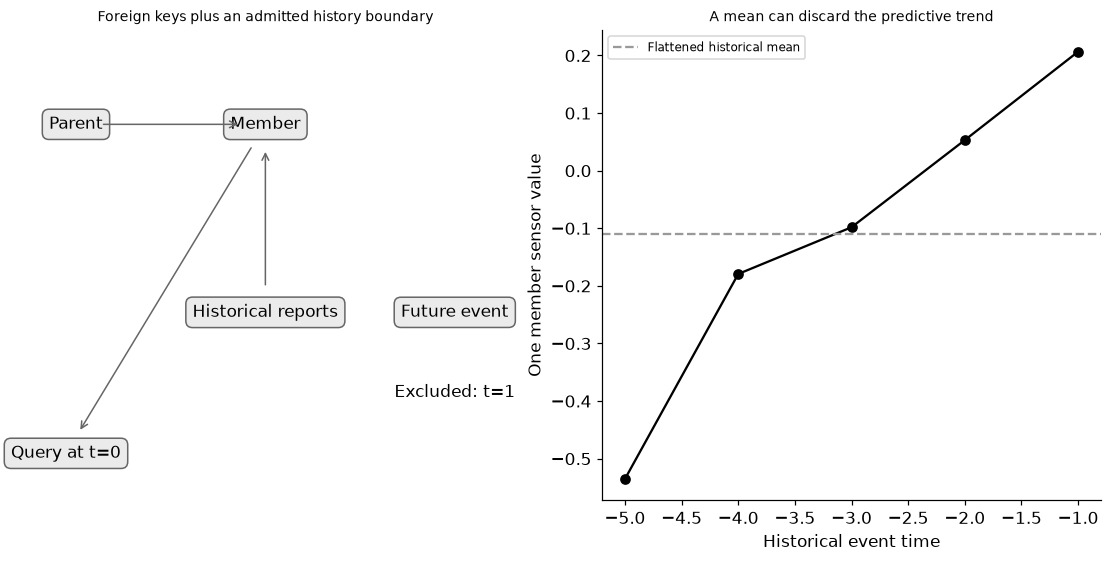

In [2]:
import copy,hashlib
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
N=64;times=np.array([-5.,-4.,-3.,-2.,-1.,1.],dtype=np.float32);reports=times+.2;history=(times<=0)&(reports<=0);parent_id=np.repeat(np.arange(16),4);anchors=np.r_[np.full(32,-2.),np.zeros(32)];absolute_reports=anchors[:,None]+reports;label_reports=anchors+reports[-1]
assert np.all(label_reports[:32]<=0) and np.all(label_reports[32:]>0)
assert np.all(absolute_reports[:,history]<=anchors[:,None])
def databases(number):
    parent=rng.normal(size=(number,16,1)).astype(np.float32);own=rng.normal(size=(number,N,2)).astype(np.float32);base=np.concatenate([own,parent[:,parent_id]],2);intercepts=rng.normal(0,.4,(number,N,1,2));slopes=rng.normal(size=(number,N,1,2));values=(intercepts+slopes*times[None,None,:,None]/3+rng.normal(0,.08,(number,N,6,2))).astype(np.float32);weights=rng.normal(size=(number,2));weights/=np.linalg.norm(weights,axis=1)[:,None];score=2*np.sum(slopes[:,:,0,:]*weights[:,None,:],2)+.3*base[:,:,0]+rng.normal(0,.3,(number,N));labels=(score>0).astype(np.int64);values[:,:,-1,:]=10*labels[:,:,None];events=np.concatenate([values,np.broadcast_to(times,(number,N,6))[:,:,:,None]],3).astype(np.float32);return torch.tensor(base),torch.tensor(events),torch.tensor(labels)
SB,SE,SY=databases(512);DB,DE,DY=databases(64);FB,FE,FY=databases(32);mask=torch.tensor(history.astype(np.float32));assert history.sum()==5 and not history[-1]
class RelationalEncoder(nn.Module):
    def __init__(self):super().__init__();self.event=nn.Sequential(nn.Linear(3,24),nn.GELU(),nn.Linear(24,24));self.member=nn.Sequential(nn.Linear(27,32),nn.GELU(),nn.Linear(32,32))
    def forward(self,base,events):message=(self.event(events)*mask[None,None,:,None]).sum(2)/mask.sum();return self.member(torch.cat([base,message],2))
class RelationalContext(nn.Module):
    def __init__(self):super().__init__();self.encoder=RelationalEncoder();self.context=nn.Linear(33,32);self.key=nn.Linear(32,32,bias=False);self.query=nn.Linear(32,32,bias=False);self.head=nn.Sequential(nn.Linear(64,32),nn.GELU(),nn.Linear(32,2))
    def forward(self,base,events,labels):
        embed=self.encoder(base,events);context=self.context(torch.cat([embed[:,:32],labels[:,:32,None].float()],2));query=self.query(embed[:,32:]);attention=torch.softmax(query@self.key(context).transpose(1,2)/np.sqrt(32),2);return self.head(torch.cat([embed[:,32:],attention@context],2))
def probabilities(model,base,events,labels):
    with torch.no_grad():return model(base,events,labels).softmax(2)[:,:,1].numpy()
model=RelationalContext();optimizer=torch.optim.Adam(model.parameters(),lr=.002);best=np.inf;trace=[]
for step in range(1500):
    ids=torch.tensor(rng.choice(512,8,replace=False));optimizer.zero_grad();logits=model(SB[ids],SE[ids],SY[ids]);loss=nn.functional.cross_entropy(logits.reshape(-1,2),SY[ids,32:].reshape(-1));loss.backward();optimizer.step()
    if (step+1)%100==0:
        score=float(np.mean((probabilities(model,DB,DE,DY)-DY[:,32:].numpy())**2));trace.append([step+1,score])
        if score<best:best=score;state=copy.deepcopy(model.state_dict());best_step=step+1
model.load_state_dict(state);pretrained=probabilities(model,FB,FE,FY);future_changed=FE.clone();future_changed[:,:,-1,:2]+=1234;mutated=probabilities(model,FB,future_changed,FY);np.testing.assert_array_equal(pretrained,mutated)
def digest(model):return hashlib.sha256(b''.join(p.detach().numpy().tobytes() for p in model.parameters())).hexdigest()
before=digest(model);probabilities(model,FB,FE,FY);assert digest(model)==before
historical=FE[:,:,history,:2].numpy();historical_t=times[history];centered_t=historical_t-historical_t.mean();mean=historical.mean(2);trend=np.sum((historical-mean[:,:,None,:])*centered_t[None,None,:,None],2)/np.sum(centered_t**2);flat=np.concatenate([FB.numpy(),mean],2);engineered=np.concatenate([flat,trend],2);predictions={'Pretrained relational context':pretrained};flat_predictions=[];trend_predictions=[];neural_predictions=[]
class PerDatabaseNeural(nn.Module):
    def __init__(self):super().__init__();self.encoder=RelationalEncoder();self.head=nn.Linear(32,2)
    def forward(self,base,events):return self.head(self.encoder(base,events))
for j in range(32):
    for features,collection in [(flat,flat_predictions),(engineered,trend_predictions)]:
        classifier=make_pipeline(StandardScaler(),LogisticRegression(C=1,max_iter=300)).fit(features[j,:32],FY[j,:32].numpy());collection.append(classifier.predict_proba(features[j,32:])[:,1])
    torch.manual_seed(SEED+j);local=PerDatabaseNeural();local_optimizer=torch.optim.Adam(local.parameters(),lr=.01)
    for step in range(100):local_optimizer.zero_grad();logits=local(FB[j:j+1,:32],FE[j:j+1,:32]);loss=nn.functional.cross_entropy(logits.reshape(-1,2),FY[j,:32]);loss.backward();local_optimizer.step()
    with torch.no_grad():neural_predictions.append(local(FB[j:j+1,32:],FE[j:j+1,32:]).softmax(2)[0,:,1].numpy())
predictions.update({'Flattened event means':np.array(flat_predictions),'Engineered historical trends':np.array(trend_predictions),'Per-database neural messages':np.array(neural_predictions)});rows=[{'predictor':name,'mean_database_Brier':float(np.mean((p-FY[:,32:].numpy())**2)),'final_databases':32,'context_members_per_database':32,'query_members_per_database':32} for name,p in predictions.items()]
# Invalid fixture exposes future outcome information explicitly and is never a valid comparator.
leaky_probability=FE[:,32:,-1,0].numpy()/10;leaky_Brier=float(np.mean((leaky_probability-FY[:,32:].numpy())**2));assert leaky_Brier==0 and np.all(parent_id[:32]<8) and np.all(parent_id[32:]>=8)
RESULTS.update(source_databases=512,development_databases=64,final_databases=32,parents_per_database=16,members_per_database=64,event_rows_per_database=384,admitted_historical_event_rows_per_database=320,context_label_report_time=float(label_reports[0]),query_label_report_time=float(label_reports[-1]),pretraining_updates=1500,pretraining_rate=.002,selected_update=best_step,development_Brier=best,pretrained_parameters=sum(p.numel() for p in model.parameters()),per_database_neural_updates=100,per_database_neural_rate=.01,comparisons=rows,future_event_intervention_max_difference=float(np.max(np.abs(pretrained-mutated))),pretrained_weights_unchanged=True,invalid_future_leak_Brier=leaky_Brier);display(pd.DataFrame(rows));print('Future-row intervention:',RESULTS['future_event_intervention_max_difference'],'Invalid future-label fixture:',leaky_Brier)
fig,axes=plt.subplots(1,2,figsize=(10,5));ax=axes[0];ax.axis('off');nodes={'Parent':(.12,.8),'Member':(.5,.8),'Historical reports':(.5,.4),'Future event':(.88,.4),'Query at t=0':(.1,.1)}
for label,(xx,yy) in nodes.items():ax.text(xx,yy,label,ha='center',va='center',transform=ax.transAxes,bbox={'boxstyle':'round,pad=.4','facecolor':'.92','edgecolor':'.4'})
for source_name,target in [('Parent','Member'),('Historical reports','Member'),('Member','Query at t=0')]:ax.annotate('',xy=nodes[target],xytext=nodes[source_name],xycoords='axes fraction',arrowprops={'arrowstyle':'->','color':'.4','shrinkA':18,'shrinkB':18})
ax.text(.88,.22,'Excluded: t=1',ha='center',transform=ax.transAxes);ax.set_title('Foreign keys plus an admitted history boundary');axes[1].plot(historical_t,historical[0,40,:,0],'o-',color='black');axes[1].axhline(historical[0,40,:,0].mean(),color='.6',linestyle='--',label='Flattened historical mean');axes[1].set(xlabel='Historical event time',ylabel='One member sensor value',title='A mean can discard the predictive trend');axes[1].legend(fontsize=8);plt.show()


<a id="relational-pretraining-and-controls"></a>
 ## Preserve the distinction between representation and training provenance
 The historical message function uses each event value and timestamp, then averages admissible messages and combines the result with member and gathered parent attributes. This is an actual small relational aggregation, not a full Kumo or OpenRFM architecture. Its cross-database pretraining differs from training a fresh neural message model on32context members per database. A carefully engineered flat representation may preserve the same valid history signal and is retained as a strong control. Here historical times have a nonzero mean, so even the naive event mean retains some slope information; it is not an intentionally uninformative baseline. Query members have different parent keys from context members, preventing a shared-parent shortcut in this constructed task. Context labels mature before the current request, while their features replay their earlier anchor; query outcomes mature afterward and are withheld. Database identities, rather than event rows, define pretraining/development/final evidence. An unavailable future event is an explicit leakage fixture; its zero Brier score is invalid evidence. Mutating it leaves admitted predictions exactly unchanged. Reusable weights do not remove the need to specify query entity, outcome window, allowed event/report times and context-label availability.


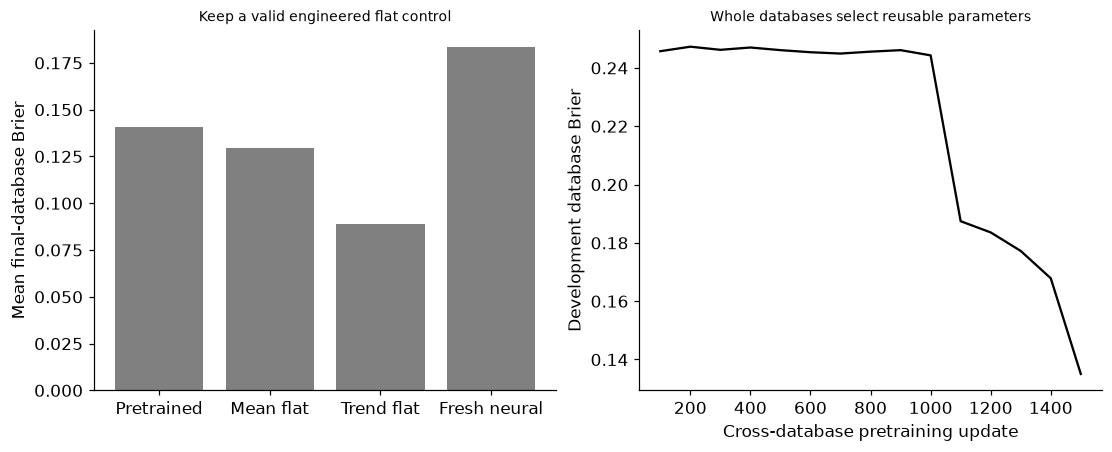

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,4));axes[0].bar(range(len(rows)),[r['mean_database_Brier'] for r in rows],color='.5');axes[0].set(xticks=range(len(rows)),xticklabels=['Pretrained','Mean flat','Trend flat','Fresh neural'],ylabel='Mean final-database Brier',title='Keep a valid engineered flat control');h=np.array(trace);axes[1].plot(h[:,0],h[:,1],color='black');axes[1].set(xlabel='Cross-database pretraining update',ylabel='Development database Brier',title='Whole databases select reusable parameters');plt.show()
assert all(np.isfinite(r['mean_database_Brier']) for r in rows)


In [4]:
summary={'example_id':'code_147','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual own cross-database relational pretraining', 'historical event messages and parent-key gathers', 'frozen labelled-context prediction on new databases', 'per-database neural and flat-feature controls', 'future-row intervention with invariant admitted predictions'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual own cross-database relational pretraining", "historical event messages and parent-key gathers", "frozen labelled-context prediction on new databases", "per-database neural and flat-feature controls", "future-row intervention with invariant admitted predictions"], "elapsed_seconds": 2.908, "example_id": "code_147", "hardware": "Darwin arm64 CPU", "results": {"admitted_historical_event_rows_per_database": 320, "comparisons": [{"context_members_per_database": 32, "final_databases": 32, "mean_database_Brier": 0.1404630028452022, "predictor": "Pretrained relational context", "query_members_per_database": 32}, {"context_members_per_database": 32, "final_databases": 32, "mean_database_Brier": 0.12972216123947938, "predictor": "Flattened event means", "query_members_per_database": 32}, {"context_members_per_database": 32, "final_databases": 32, "mean_database_Brier": 0.08873276384169645, "predictor": "Engineered historical trends", "que